<a href="https://colab.research.google.com/github/seadsejo/ml-final-task-category-prediction-model/blob/main/task_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML Task: Category Prediction Model

## We will now proceed to make a model wich will predict the category of a product based off its title. To create such a model we first require a "lab" to play and analyse data in a safe environment. For this we use Colab and its usefull ".ipynb" notebook. Before getting started we made a github repository with public access, cloned it localy to VScode and also commited the "products.csv" dataset. Now we will save a copy in github and continue on to loading the dataset and start analysis of data.

## A good ML project usualy needs to check some boxes:
1. Acquiering raw data
2. Exploratory Data Analysis (EDA)
3. Data cleaning and processing
4. Feature engineering
5. Algorithm choosing
6. Model training
7. Evaluation and testing
8. Saving and exporting a model

In [1]:
# We load about all of the libraries we could need at the start
# Dividing them in chunks is helpfull, especialy when you need to check if
# one is missing or you have an error
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report



##########################
# Load dataset from GitHub
url="https://raw.githubusercontent.com/seadsejo/ml-final-task-category-prediction-model/main/data/products.csv"

df = pd.read_csv(url)

# Show first few rows
print("\nFirst 20 rows:")
display(df.head(20))


First 20 rows:


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023
5,6,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,6,Mobile Phones,SB-2202-CH,3444.0,1.6,11/27/2022
6,7,apple iphone 8 plus 64 gb space grey,7,Mobile Phones,QJ-3229-QP,3171.0,1.2,3/29/2022
7,8,apple iphone 8 plus 64gb space grey,8,Mobile Phones,ES-1396-OR,2919.0,4.5,5/21/2024
8,9,apple iphone 8 plus 64gb space grey,9,Mobile Phones,VU-2032-FY,130.0,3.4,5/11/2022
9,10,apple iphone 8 plus 64gb space grey,10,Mobile Phones,WI-6394-GG,1685.0,3.8,2/9/2024


# Exploratory Data Analysis (EDA)
## In this part we will see what type of data we are working with, what we need and don't need, what to keep, what to discard, how could certain data affect the outcome and so on. In this step we basicly just explore and play arround to figure out what to clean in the next step.
## Our model is only as good as our training data is clean!

In [8]:
# What to keep,
# what to use for model training?
# How is this data valuable and or corelated?
print("Shape:", df.shape)

print("\nInfo:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCategories:")
print(df[" Category Label"].unique())        # lstrip?
print(df[" Category Label"].value_counts())

# Prazni str i duplikati
print("\nEmpty product titles:")
print((df["Product Title"].str.strip() == "").sum())

print("Duplicate Product Titles:")
print(df["Product Title"].duplicated().sum())

print("\nDuplicates:")
print(df.duplicated().sum())
print(df[df.duplicated()])

Shape: (35311, 8)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   product ID       35311 non-null  int64  
 1   Product Title    35139 non-null  object 
 2   Merchant ID      35311 non-null  int64  
 3    Category Label  35267 non-null  object 
 4   _Product Code    35216 non-null  object 
 5   Number_of_Views  35297 non-null  float64
 6   Merchant Rating  35141 non-null  float64
 7    Listing Date    35252 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 2.2+ MB

Missing Values:
product ID           0
Product Title      172
Merchant ID          0
 Category Label     44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
 Listing Date       59
dtype: int64

Categories:
['Mobile Phones' nan 'Mobile Phone' 'TVs' 'CPUs' 'CPU' 'Digital Cameras'
 'Microwaves' 'Dishwashers' 'Washing Machines

### We notice many duplicate categories like:
- **'Freezers', 'Fridge Freezers', 'Fridges', 'fridge'**
- **'CPUs', 'CPU'**
- **'Mobile Phones', 'Mobile Phone'**

### In the next few cells we will atempt to group by title and category to find out what is going on. To be more precise, we need to know if a certain title exists in all categories and how to unite them in one.

### Also noteworthy:
- No duplicates, but duplicated product titles exist, probably because of category problem mentioned before
- Aside from categories being duplicated, their names need cleaning or standardisation; turn to lower case and whitespace removal
- CPU and Phones conflict will be resolved by combining them in one but with fridges we need to be more carefull, there are more factors to account
- Fridges, freezers and fridge-freezers are three different categories of products

In [11]:

title_categories = df.groupby("Product Title")[" Category Label"].nunique()

conflicting_titles = title_categories[title_categories > 1]

print("Titles with conflicting categories:", len(conflicting_titles))

df[df["Product Title"].isin(conflicting_titles.index)].sort_values("Product Title")

Titles with conflicting categories: 62


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
8101,14227,amd ad9800ahabbox cpu cooler amd socket a12 98...,3,CPUs,FC-6221-CX,604.0,5.0,8/14/2024
8099,14225,amd ad9800ahabbox cpu cooler amd socket a12 98...,17,CPU,MR-1502-NT,4570.0,3.3,9/25/2024
33365,45306,amica uc1503 60cm built under larder fridge,6,Fridges,PX-5076-EE,4096.0,1.1,12/24/2022
33368,45309,amica uc1503 60cm built under larder fridge,3,fridge,RA-7105-NB,2427.0,3.2,6/30/2022
33366,45307,amica uc1503 60cm built under larder fridge,15,Fridges,ZQ-3221-GX,3080.0,1.3,1/6/2024
...,...,...,...,...,...,...,...,...
33196,45106,tall fridge with ice box,347,Fridges,RD-6469-WI,3676.0,1.7,9/30/2022
33344,45277,zanussi zba22421sa built in fridge with freezer,293,fridge,LS-8416-IS,4242.0,2.3,NaN
33343,45276,zanussi zba22421sa built in fridge with freezer,294,Fridges,NP-8553-KY,2952.0,2.7,11/23/2022
33275,45193,zanussi zrg15805wa under counter fridge with i...,293,Fridges,VZ-0499-AD,4389.0,4.0,4/2/2022


In [13]:
# Here we see wich product title belongs to more than one category,
# meaning the conflict we are trying to resolve is due to categories being
# "split" so to say
conflict_summary = (
    df[df["Product Title"].isin(conflicting_titles.index)]
    .groupby("Product Title")[" Category Label"]
    .agg(lambda x: list(x.dropna().unique()))
    .reset_index()
    )

print(conflict_summary.to_string(index=False))

                                                                                 Product Title                Category Label
                                         amd ad9800ahabbox cpu cooler amd socket a12 9800e am4                   [CPU, CPUs]
                                                   amica uc1503 60cm built under larder fridge             [Fridges, fridge]
                                   archos diamond gamma 5.5 dual sim 4g 3gb 32gb 3000mah black [Mobile Phones, Mobile Phone]
                                                               blomberg kgm9550 fridge freezer    [Fridge Freezers, Fridges]
                                                                             blomberg tsm1551p             [Fridges, fridge]
                                   bosch kil42vs30g series 4 built in single door fridge white             [fridge, Fridges]
                                   bosch kir21vf30g series 4 built in single door fridge white             [fridge, Fridges]


In [15]:
# Here we use random selection to get some examples to
# better understand our fridges
categories_to_check = [
    "Fridges",
    "Freezers",
    "Fridge Freezers"
    ]

for category in categories_to_check:
    print(f"\n--- {category} ---")

    print(
        df[df[" Category Label"] == category]["Product Title"]
        .dropna()
        .sample(10, random_state=42)
        .to_string(index=False)
        )


--- Fridges ---
         swan free standing larder fridge in green
smeg fab5rpb 40cm pastel blue small 50 s styler...
               montpellier mab340r tall fridge red
                 siemens ki20rv52 einbau k hlger t
samsung rr39m7340sa fridge larder 350 litres wa...
fridgemaster mur4996 49.4cm wide freestanding f...
 siemens ki24lv52 einbau k hlger t mit gefrierfach
fridgemaster mur4892 48cm wide freestanding und...
     smeg fab10rne 50s style black home bar fridge
          liebherr iks1624 built in ice box fridge

--- Freezers ---
whirlpool afb1843a 178cm integrated in column f...
                       beko cf1300ap chest freezer
                                  gorenje fhe152iw
                             igenix ig350f freezer
fridgemaster mtz55160 55cm wide freestanding up...
              beko free standing freezer in silver
                hotpoint tzul163xfh fridge freezer
   liebherr igs1624 integrated smart frost freezer
siemens gs36nai31 tall freezer a energy rating 

In [17]:
# We figured out that our "confict" is just data being separated
# to a few categories instead of one
# Now let's temporarily resolve that and see if there is still something left
category_mapping = {
    "CPU": "CPUs",
    "Mobile Phone": "Mobile Phones",
    "fridge": "Fridges"
    }

temp_df = df.copy()

temp_df[" Category Label"] = temp_df[" Category Label"].replace(
    category_mapping
    )

temp_conflicts = (
    temp_df.groupby("Product Title")[" Category Label"]
    .nunique()
    )

temp_conflicts = temp_conflicts[temp_conflicts > 1]

print("Remaining conflicting titles:", len(temp_conflicts))

Remaining conflicting titles: 2


In [18]:
# Two remain
print(
    temp_df[temp_df["Product Title"].isin(temp_conflicts.index)]
    [["Product Title", " Category Label"]]
    .to_string(index=False)
    )

                                  Product Title   Category Label
bosch kur15a50gb integrated undercounter fridge Washing Machines
                blomberg kgm9550 fridge freezer  Fridge Freezers
bosch kur15a50gb integrated undercounter fridge          Fridges
                blomberg kgm9550 fridge freezer          Fridges


In [20]:
for title in temp_conflicts.index:
    print(f"\n{title}")
    print(
        temp_df.loc[
            temp_df["Product Title"] == title,
            " Category Label"
        ].value_counts()
    )


blomberg kgm9550 fridge freezer
 Category Label
Fridge Freezers    1
Fridges            1
Name: count, dtype: int64

bosch kur15a50gb integrated undercounter fridge
 Category Label
Washing Machines    1
Fridges             1
Name: count, dtype: int64


In [22]:
# We will fix the data manualy, since we can
# This is temporary we won't forget to add it to data cleaning
temp_df.loc[
    temp_df["Product Title"] == "bosch kur15a50gb integrated undercounter fridge",
    " Category Label"
] = "Fridges"

temp_df.loc[
    temp_df["Product Title"] == "blomberg kgm9550 fridge freezer",
    " Category Label"
] = "Fridge Freezers"

### EDA Product Title len
- Avg len is 53, median is close at 52 caracters
- The shortest titles contain only 5 characters, while the longest contain 200
- Short titles such as lg q6 and lg g5 are valid product names, not necessarily incomplete data
- The 10 shortest and 10 longest titles all belong to the Mobile Phones category
- Long titles often contain additional technical specifications and marketing descriptions
- Title length alone may not be sufficient for reliable product classification.
- Four titles reach exactly 200 characters, later on we found evidence of unfinished titles implying a 200 chr. limit

In [23]:
#
print("Data type of Product Title column:",
      df["Product Title"].dtype)

print("\nFirst 10 product titles:")
print(df["Product Title"].head(10))

print("\nTop 20 most frequent product titles:")
print(df["Product Title"].value_counts().head(20))

df["title_length"] = df["Product Title"].str.len()

df["title_length"].describe()



Data type of Product Title column: object

First 10 product titles:
0                      apple iphone 8 plus 64gb silver
1                  apple iphone 8 plus 64 gb spacegrau
2    apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...
3                  apple iphone 8 plus 64gb space grey
4    apple iphone 8 plus gold 5.5 64gb 4g unlocked ...
5    apple iphone 8 plus gold 5.5 64gb 4g unlocked ...
6                 apple iphone 8 plus 64 gb space grey
7                  apple iphone 8 plus 64gb space grey
8                  apple iphone 8 plus 64gb space grey
9                  apple iphone 8 plus 64gb space grey
Name: Product Title, dtype: object

Top 20 most frequent product titles:
Product Title
washing machine                                                           90
built in fully integrated dishwasher                                      35
frost free fridge freezer                                                 34
washer dryer                                                    

,title_length
count,35139.000000
mean,52.981701
std,22.438310
min,5.000000
25%,38.500000
50%,52.000000
75%,65.000000
max,200.000000


In [27]:
# Shortest and longest titles
shortest_titles = df.nsmallest(10, "title_length")[
    ["Product Title", " Category Label", "title_length"]
    ]

longest_titles = df.nlargest(10, "title_length")[
    ["Product Title", " Category Label", "title_length"]
    ]

print("Shortest titles: ")
print(shortest_titles)
print("\nLongest titles: ")
print(longest_titles)

Shortest titles: 
     Product Title  Category Label  title_length
884          lg q6   Mobile Phones           5.0
1720         lg g5   Mobile Phones           5.0
2666         lg g4   Mobile Phones           5.0
2732         lg g2   Mobile Phones           5.0
3358         lg k7   Mobile Phones           5.0
3519         lg g3   Mobile Phones           5.0
1261        lg v30   Mobile Phones           6.0
3422        lg g4c   Mobile Phones           6.0
3459        lg l40   Mobile Phones           6.0
3482        lg f60    Mobile Phone           6.0

Longest titles: 
                                          Product Title  Category Label  \
1853  ulefone armor2 ip68 rugged unlocked 4g cellpho...   Mobile Phones   
3087  vkworld s8 5.99inch fhd 2160 1080 18 9 android...   Mobile Phones   
3134  vkworld t2 plus 4.2 inch dual screen flip phon...   Mobile Phones   
3207  ulefone power 2 smartphone cellphone mobilepho...   Mobile Phones   
2384  ulefone power 5 big battery 4g mobile 13000m

In [28]:
df["title_length"].value_counts().sort_index(ascending=False).head(15)

,count
title_length,
200.0,4
199.0,6
197.0,2
195.0,2
194.0,1
192.0,4
190.0,7
188.0,2
187.0,1


In [31]:
# Here we see that our titles are actually limited to 200 chr
longest_titles = df.loc[
    df["title_length"] == 200,
    ["Product Title", " Category Label", "title_length"]
    ]

print(longest_titles.to_string(index=False, max_colwidth=None))

                                                                                                                                                                                           Product Title  Category Label  title_length
ulefone armor2 ip68 rugged unlocked 4g cellphone smartphone mobilephone 5 inch fhd screen 6gb 64gb 8 core powerful helio p25 2.6ghz cpu super power savery 4700mah battery best pe 2.0 fast charge water   Mobile Phones         200.0
vkworld s8 5.99inch fhd 2160 1080 18 9 android7.0 bezel less face id smartphone mtk6750t octa memory 4gb 64gb battery 5500mah back16mp 5mp dual camera and front 13mp fingerprint contains uk specificat   Mobile Phones         200.0
vkworld t2 plus 4.2 inch dual screen flip phone android 7.0 3g ram 32g rom big battery 2000mah with big button physical keyboard smartphone aac speaker fm radio bluetooth dual sim 4g unlocked sim free   Mobile Phones         200.0
ulefone power 2 smartphone cellphone mobilephone super powerful battery 6050

In [32]:
# Title len per category,
df.groupby(" Category Label")["title_length"].describe()

,count,mean,std,min,25%,50%,75%,max
Category Label,,,,,,,,
CPU,84.0,68.630952,26.812504,18.0,52.75,63.5,77.75,190.0
CPUs,3747.0,66.985322,20.040537,11.0,55.00,65.0,76.00,159.0
Digital Cameras,2689.0,50.115284,24.548060,6.0,34.00,44.0,61.00,180.0
Dishwashers,3405.0,50.206755,17.989980,10.0,39.00,51.0,61.00,192.0
Freezers,2201.0,48.769650,18.209715,10.0,37.00,47.0,60.00,168.0
Fridge Freezers,5470.0,55.237477,20.468326,9.0,42.00,54.0,68.00,170.0
Fridges,3436.0,48.576834,18.414970,8.0,36.00,46.0,62.00,173.0
Microwaves,2328.0,51.811856,18.798911,11.0,39.00,52.0,65.00,164.0
Mobile Phone,55.0,58.581818,40.775669,6.0,36.00,46.0,64.50,177.0


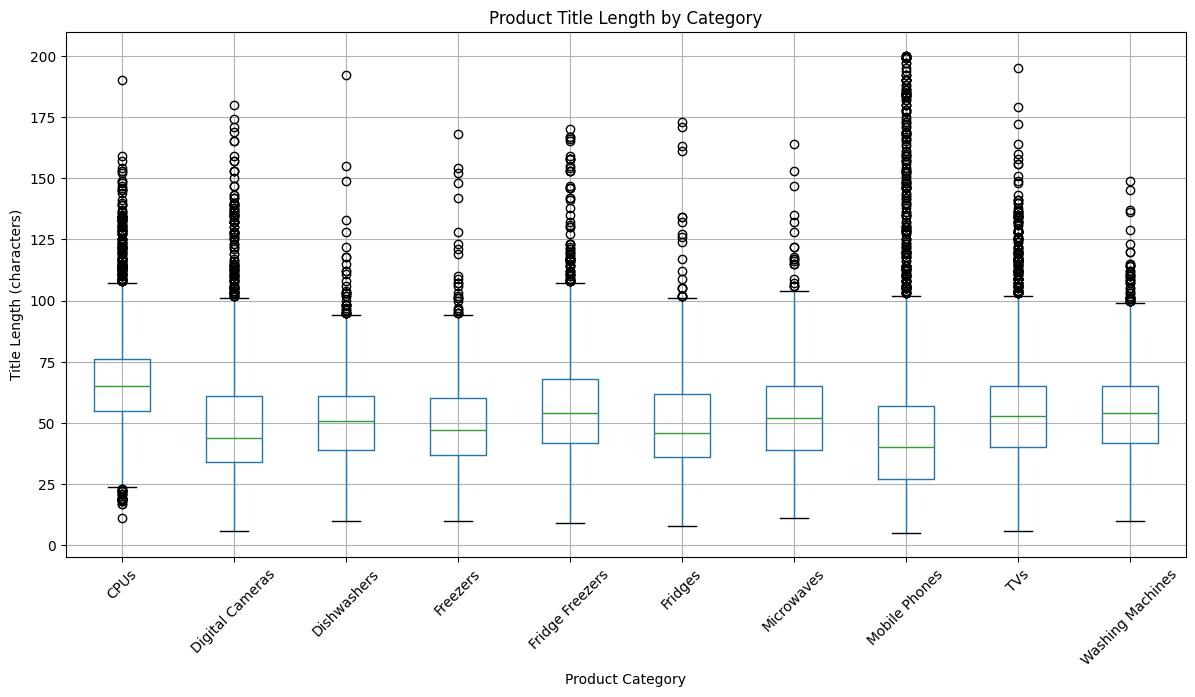

In [33]:
plot_df = df.copy()

category_mapping = {
    "CPU": "CPUs",
    "Mobile Phone": "Mobile Phones",
    "fridge": "Fridges"
    }


plot_df[" Category Label"] = (
    plot_df[" Category Label"].replace(category_mapping)
    )


plot_df.boxplot(
    column="title_length",
    by=" Category Label",
    figsize=(14, 7),
    rot=45
    )


plt.title("Product Title Length by Category")
plt.suptitle("")
plt.xlabel("Product Category")
plt.ylabel("Title Length (characters)")
plt.show()

In [35]:
df["word_count"] = df["Product Title"].str.split().str.len()

df["word_count"].describe()

,word_count
count,35139.000000
mean,8.665358
std,4.164396
min,1.000000
25%,6.000000
50%,8.000000
75%,11.000000
max,37.000000


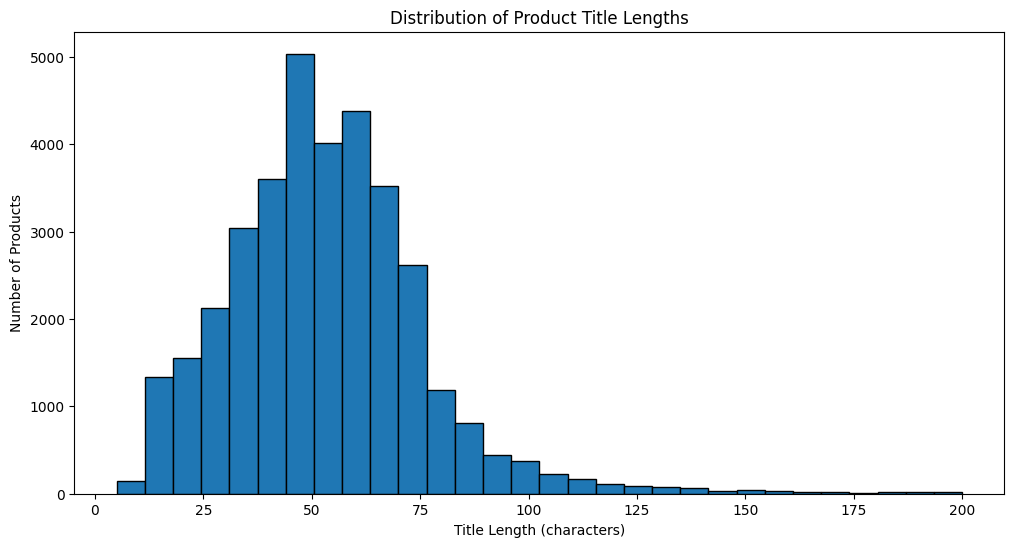

In [29]:
plt.figure(figsize=(12, 6))

plt.hist(df["title_length"].dropna(), bins=30, edgecolor="black")

plt.title("Distribution of Product Title Lengths")
plt.xlabel("Title Length (characters)")
plt.ylabel("Number of Products")

plt.show()